In [1]:
import json

import numpy as np
import pandas as pd
import xarray

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from scipy.stats import linregress
from utils import ray_casting, plot_annual_mean_and_trend
from utils import count_events, count_longest_event

ERROR 1: PROJ: proj_create_from_database: Open of /opt/conda/envs/xarray/share/proj failed


We want to define our country.

In [2]:
COUNTRY = "Yemen"
DOMAIN  = "AFR-22"

DATE0, DATE1 = "1980-01-01", "2005-12-31"
YEARS        = np.arange(1980, 2006)

In [3]:
with open("ne_110m_admin_0_countries.geojson", "r", encoding="utf-8") as f:
    countries = json.load(f)

# Extract Spain's geometry
country = next(feature["geometry"]
               for feature in countries["features"]
               if feature["properties"]["ADMIN"] == COUNTRY)

# Get the exterior coordinates
if country["type"] == "Polygon":
    polygons = [country["coordinates"]]
elif country["type"] == "MultiPolygon":
    polygons = country["coordinates"]
else:
    raise ValueError(f"Unsupported geometry type: {country['type']}")

coords = [coord for polygon in polygons for coord in polygon[0]]
longitudes, latitudes = [p[0] for p in coords], [p[1] for p in coords]

min_lon, min_lat, max_lon, max_lat = min(longitudes), min(latitudes), max(longitudes), max(latitudes)

print(f"Bounding box: ({min_lon}, {min_lat}, {max_lon}, {max_lat})")

Bounding box: (42.604873, 12.58595, 53.108573, 19.000003)


# ERA5

In [4]:
%%time

era5 = xarray.open_dataset("https://hub.ipcc.ifca.es/thredds/dodsC/fao/observations/ERA5/0.25/ERA5_025.ncml")
if (min_lon < 0) and (max_lon < 0):
    era5 = era5[["tp", "t2mx", "t2mn"]].sel(
    longitude=slice(min_lon+360, max_lon+360),
    latitude=slice(max_lat, min_lat),
    time=slice(DATE0, DATE1)).chunk({"time": 2500}).load(scheduler="processes", num_workers=4)
    era5 = era5.assign_coords(longitude=((era5.longitude + 180) % 360) - 180).sortby("longitude")
elif abs(min_lon) > max_lon:
    era5 = xarray.merge([
        era5[["tp", "t2mx", "t2mn"]].sel(
            longitude=slice(None, max_lon),
            latitude=slice(max_lat, min_lat),
            time=slice(DATE0, DATE1)).chunk({"time": 2500}).load(scheduler="processes", num_workers=4),
        era5[["tp", "t2mx", "t2mn"]].sel(
            longitude=slice(era5["longitude"].max() - abs(min_lon), None),
            latitude=slice(max_lat, min_lat),
            time=slice(DATE0, DATE1)).chunk({"time": 2500}).load(scheduler="processes", num_workers=4)
    ], join="outer", compat="no_conflicts")
    era5 = era5.assign_coords(longitude=((era5.longitude + 180) % 360) - 180).sortby("longitude")
else:
    era5 = era5[["tp", "t2mx", "t2mn"]].sel(
    longitude=slice(min_lon, max_lon),
    latitude=slice(max_lat, min_lat),
    time=slice(DATE0, DATE1)).chunk({"time": 2500}).load(scheduler="processes", num_workers=4)

CPU times: user 489 ms, sys: 411 ms, total: 900 ms
Wall time: 5.98 s


Calculate the mask.

In [5]:
lat, lon = era5.coords['latitude'], era5.coords['longitude']
mask = np.zeros((len(lat), len(lon)), dtype=bool)

for i, lat_val in enumerate(lat.values):
    for j, lon_val in enumerate(lon.values):
        mask[i, j] = ray_casting(lon_val, lat_val, coords)

In [6]:
prcptot = (era5["tp"] * 1000).resample({"time": "YE"}).sum()
dd      = ((era5["tp"] * 1000) <= 1).resample({"time": "YE"}).sum()

cdd     = xarray.apply_ufunc(
    count_longest_event,
    ((era5["tp"] * 1000) < 1).groupby("time.year"),
    input_core_dims=[["time"]],
    output_core_dims=[[]],
    vectorize=True,
    output_dtypes=[int]).rename({"year": "time"})

cwd     = xarray.apply_ufunc(
    count_longest_event,
    ((era5["tp"] * 1000) > 1).groupby("time.year"),
    input_core_dims=[["time"]],
    output_core_dims=[[]],
    vectorize=True,
    output_dtypes=[int]).rename({"year": "time"})

r20     = ((era5["tp"] * 1000) > 20).resample({"time": "YE"}).sum()

su      = ((era5["t2mx"] - 273.15) > 25).resample({"time": "YE"}).sum()
tr      = ((era5["t2mn"] - 273.15) > 20).resample({"time": "YE"}).sum()

hwvs    = xarray.apply_ufunc(
    lambda x: count_events(x, 3),
    ((era5["t2mx"] - 273.15) > 35).groupby("time.year"),
    input_core_dims=[["time"]],
    output_core_dims=[[]],
    vectorize=True,
    output_dtypes=[int]).rename({"year": "time"})

In [7]:
# Calculate slope (mm/year) and p-value at each grid cell
def calc_trend(y, years):
    # valid = np.isfinite(y)
    valid = np.isfinite(y) & np.isfinite(years)

    if valid.sum() < 3:
        return np.nan, np.nan

    result = linregress(years[valid], y[valid])
    return result.slope, result.pvalue

def mean_and_trend(data, years):
    annual_mean = data.mean("time")
    trend, pvalue = xarray.apply_ufunc(
        calc_trend,
        data, years,
        input_core_dims=[["time"], ["time"]],
        output_core_dims=[[], []],
        vectorize=True,
        output_dtypes=[float, float],
    )

    return annual_mean, trend, pvalue

prcptot_annual_mean, prcptot_trend, prcptot_pvalue = mean_and_trend(prcptot, YEARS)
dd_annual_mean, dd_trend, dd_pvalue = mean_and_trend(dd, YEARS)
cdd_annual_mean, cdd_trend, cdd_pvalue = mean_and_trend(cdd, YEARS)
cwd_annual_mean, cwd_trend, cwd_pvalue = mean_and_trend(cwd, YEARS)
r20_annual_mean, r20_trend, r20_pvalue = mean_and_trend(r20, YEARS)

su_annual_mean, su_trend, su_pvalue = mean_and_trend(su, YEARS)
tr_annual_mean, tr_trend, tr_pvalue = mean_and_trend(tr, YEARS)
hwvs_annual_mean, hwvs_trend, hwvs_pvalue = mean_and_trend(hwvs, YEARS)

In [8]:
results = xarray.Dataset({
    "prcptot_mean": prcptot_annual_mean,
    "prcptot_trend": prcptot_trend,
    "prcptot_pvalue": prcptot_pvalue,

    "dd_mean": dd_annual_mean,
    "dd_trend": dd_trend,
    "dd_pvalue": dd_pvalue,

    "r20_mean": r20_annual_mean,
    "r20_trend": r20_trend,
    "r20_pvalue": r20_pvalue,

    "cdd_mean": cdd_annual_mean,
    "cdd_trend": cdd_trend,
    "cdd_pvalue": cdd_pvalue,

    "cwd_mean": cwd_annual_mean,
    "cwd_trend": cwd_trend,
    "cwd_pvalue": cwd_pvalue,
})

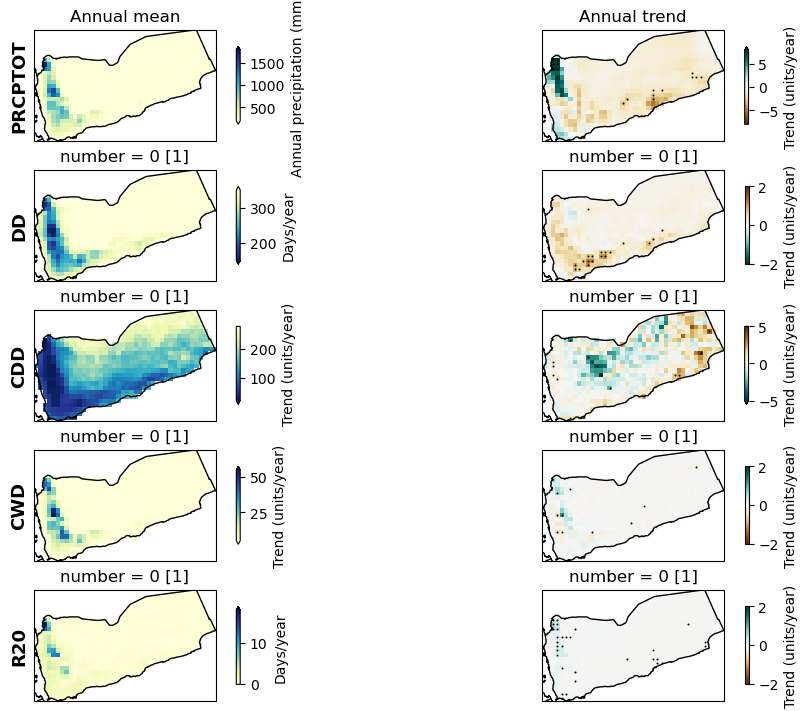

In [9]:
settings = {
    "prcptot": {
        "mean": {"cmap": "YlGnBu", "vmin": 200, "vmax": 1800},
        "trend": {"cmap": "BrBG", "vmin": -8, "vmax": 8},
    },
    "dd": {
        "mean": {"cmap": "YlGnBu_r", "vmin": 150, "vmax": 350},
        "trend": {"cmap": "BrBG_r", "vmin": -2, "vmax": 2},
    },
    "cdd": {
        "mean": {"cmap": "YlGnBu_r", "vmin": 25, "vmax": 275},
        "trend": {"cmap": "BrBG_r", "vmin": -5, "vmax": 5},
    },
    "cwd": {
        "mean": {"cmap": "YlGnBu", "vmin": 5, "vmax": 55},
        "trend": {"cmap": "BrBG", "vmin": -2, "vmax": 2},
    },
    "r20": {
        "mean": {"cmap": "YlGnBu", "vmin": 0, "vmax": 18},
        "trend": {"cmap": "BrBG", "vmin": -2, "vmax": 2},
    },
}

indices = ["prcptot", "dd", "cdd", "cwd", "r20"]
columns = ["mean", "trend"]

titles = [
    "Annual mean",
    "Annual trend",
]

fig, axes = plot_annual_mean_and_trend(results, mask, settings, indices, columns, titles, (min_lon, max_lon, min_lat, max_lat))
plt.show()

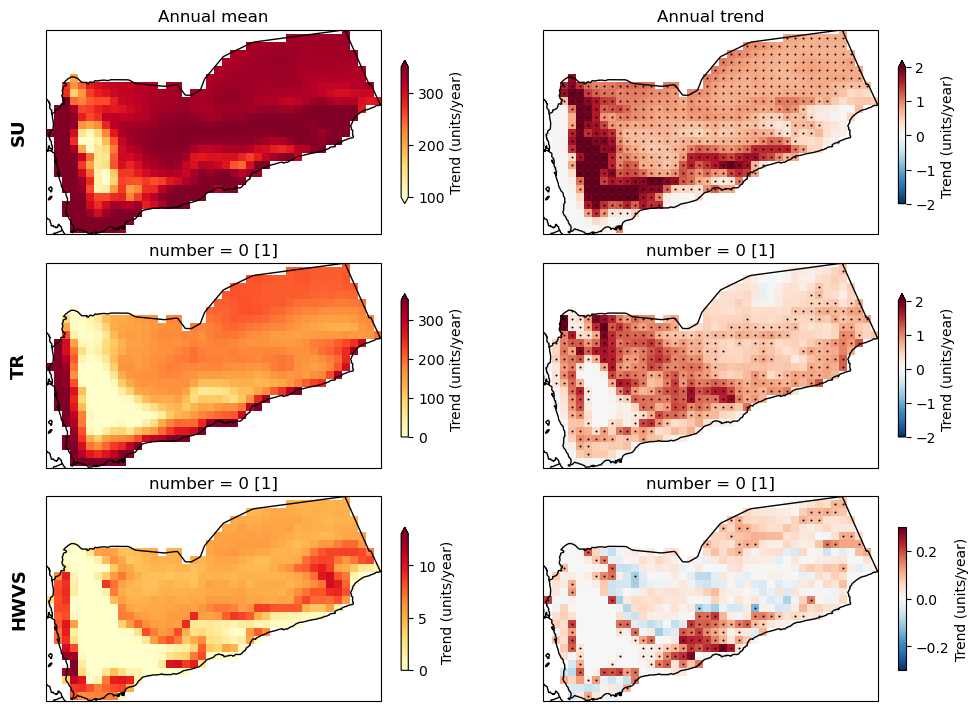

In [10]:
results = xarray.Dataset({
    "su_mean": su_annual_mean,
    "su_trend": su_trend,
    "su_pvalue": su_pvalue,

    "tr_mean": tr_annual_mean,
    "tr_trend": tr_trend,
    "tr_pvalue": tr_pvalue,

    "hwvs_mean": hwvs_annual_mean,
    "hwvs_trend": hwvs_trend,
    "hwvs_pvalue": hwvs_pvalue,
})

settings = {
    "su": {
        "mean": {"cmap": "YlOrRd", "vmin": 100, "vmax": 350},
        "trend": {"cmap": "RdBu_r", "vmin": -2, "vmax": 2},
    },
    "tr": {
        "mean": {"cmap": "YlOrRd", "vmin": 0, "vmax": 350},
        "trend": {"cmap": "RdBu_r", "vmin": -2, "vmax": 2},
    },
    "hwvs": {
        "mean": {"cmap": "YlOrRd", "vmin": 0, "vmax": 13},
        "trend": {"cmap": "RdBu_r", "vmin": -0.3, "vmax": 0.3},
    },
}

indices = ["su", "tr", "hwvs"]
columns = ["mean", "trend"]

titles = [
    "Annual mean",
    "Annual trend",
]

fig, axes = plot_annual_mean_and_trend(results, mask, settings, indices, columns, titles, (min_lon, max_lon, min_lat, max_lat))
plt.show()

# CORDEX-CORE

In [11]:
df = pd.read_csv("https://hub.ipcc.ifca.es/thredds/fileServer/inventories/cava.csv")

subset_raw = df[(df["location"].str.contains(DOMAIN)) & (df["location"].str.contains('historical')) & (df["location"].str.contains('/interp025/'))]
subset_bc  = df[(df["location"].str.contains(DOMAIN)) & (df["location"].str.contains('historical')) & (df["location"].str.contains('/interp025bc/'))]

max_lat, min_lat, min_lon, max_lon = (
    era5["latitude"].max().item(),
    era5["latitude"].min().item(),
    era5["longitude"].min().item(),
    era5["longitude"].max().item())

In [12]:
def harmonize_models(subset, vnames, time0, time1, lat0, lat1, lon0, lon1):
    dss = []
    model_coord = subset["model"] + ":" + subset["rcm"]
    for location in subset["location"]:
        ds = xarray.open_dataset(location)

        country_bbox = ds[vnames].sel(
            longitude=slice(lon0, lon1),
            latitude=slice(lat0, lat1))
    
        time_subset = country_bbox.sel(time=slice(time0, time1))

        # need to load into memory now before any calendar handling
        ds = time_subset.chunk({"time": 1000}).load(scheduler="processes", num_workers=4).convert_calendar("standard", align_on="date")
        normalized_time = pd.DatetimeIndex(ds.time.values).normalize()
        ds = ds.assign_coords(time=normalized_time)
    
        dss.append(ds)

    ds = xarray.concat(
        dss,
        dim=xarray.IndexVariable("model", model_coord),
        join="outer",
        coords="minimal")

    return ds

In [13]:
%%time

ds_raw = harmonize_models(subset_raw, ["pr", "tasmin", "tasmax"], "1980-01-01", "2006-01-01", max_lat, min_lat, min_lon, max_lon)
ds_bc  = harmonize_models(subset_bc , ["pr", "tasmin", "tasmax"], "1980-01-01", "2006-01-01", max_lat, min_lat, min_lon, max_lon)

CPU times: user 5.59 s, sys: 4.74 s, total: 10.3 s
Wall time: 1min 21s


# Compute indices

## PRCPTOT

In [14]:
prcptot_daily_raw = (ds_raw["pr"] * 86400).resample({"time": "ME"}).mean().sum("time")
prcptot_daily_bc  = (ds_bc["pr"] * 86400).resample({"time": "ME"}).mean().sum("time")
prcptot_daily_era5 = (era5["tp"] * 1000).resample({"time": "ME"}).mean().sum("time")

In [15]:
prcptot_raw = prcptot_daily_raw - prcptot_daily_era5
prcptot_bc  = prcptot_daily_bc  - prcptot_daily_era5

PRCPTOT = xarray.concat([prcptot_raw, prcptot_bc], dim=xarray.IndexVariable("source", ["raw", "bc"]))
PRCPTOT.attrs["long_name"] = "mm"

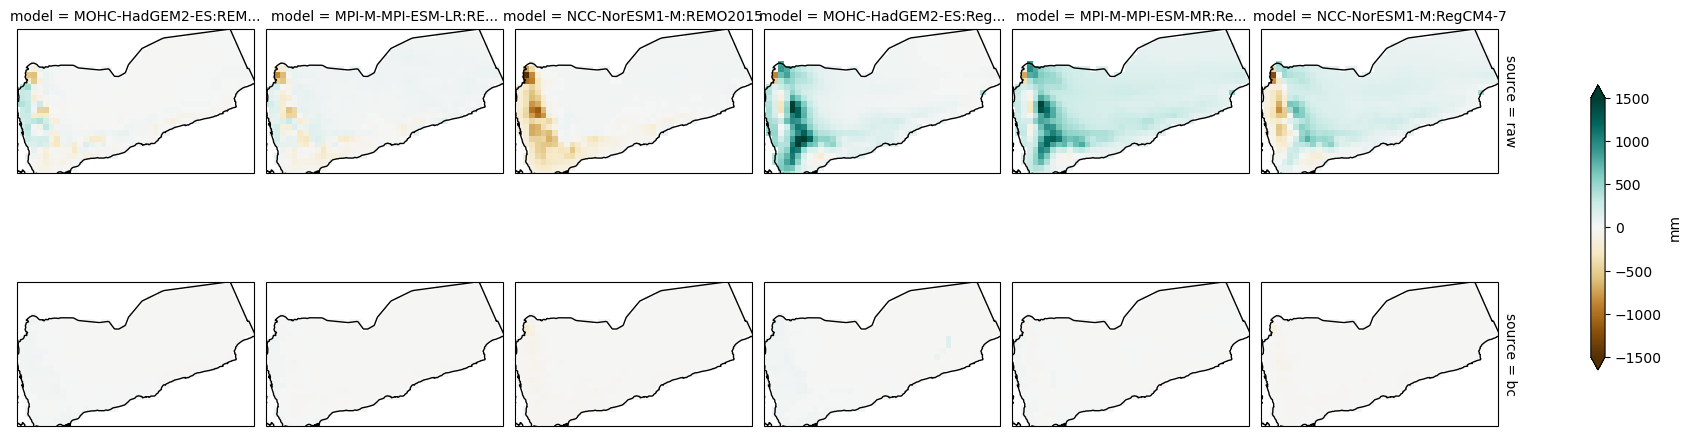

In [16]:
plot = PRCPTOT.where(mask).plot(col="model", row="source", vmin=-1500, vmax=1500, cmap="BrBG",
             subplot_kws=dict(projection=ccrs.PlateCarree(central_longitude=0)),
             cbar_kwargs={"shrink": .5},
             transform=ccrs.PlateCarree())

for ax in plot.axs.flatten():
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS, linewidth=1, edgecolor="black")
    ax.set_extent((min_lon, max_lon, min_lat, max_lat), ccrs.PlateCarree())

## DD

In [17]:
# Assumption: DD means days with precipitation < 1 mm
dd_daily_raw = ((ds_raw["pr"] * 86400) <= 1).resample({"time": "ME"}).mean()
dd_daily_bc  = ((ds_bc["pr"] * 86400) <= 1).resample({"time": "ME"}).mean()
dd_daily_era5 = ((era5["tp"] * 1000) <= 1).resample({"time": "ME"}).mean()

In [18]:
DD_raw = dd_daily_raw.sum("time") - dd_daily_era5.sum("time")
DD_bc  = dd_daily_bc.sum("time") - dd_daily_era5.sum("time")

DD = xarray.concat([DD_raw, DD_bc], dim=xarray.IndexVariable("source", ["raw", "bc"]))
DD.attrs["long_name"] = "N° days"

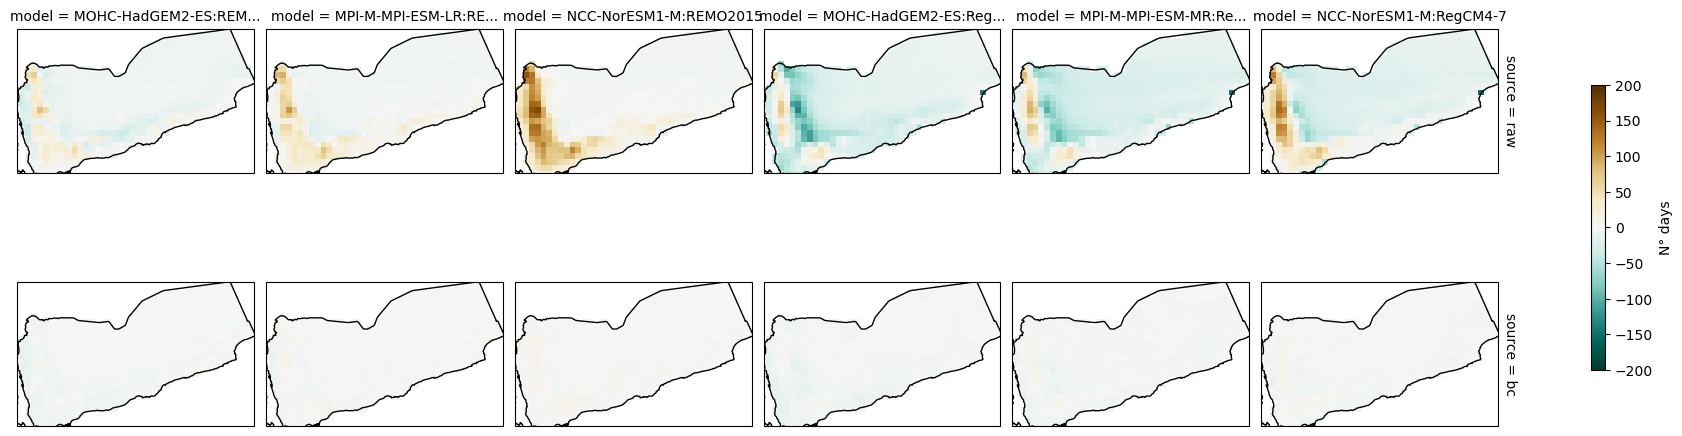

In [19]:
plot = DD.where(mask).plot(col="model", row="source", vmin=-200, vmax=200, cmap="BrBG_r",
             subplot_kws=dict(projection=ccrs.PlateCarree(central_longitude=0)),
             cbar_kwargs={"shrink": .5},
             transform=ccrs.PlateCarree())

for ax in plot.axs.flatten():
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS, linewidth=1, edgecolor="black")
    ax.set_extent((min_lon, max_lon, min_lat, max_lat), ccrs.PlateCarree())

## CDD

In [20]:
cdd_monthly_raw     = xarray.apply_ufunc(
    count_longest_event,
    ((ds_raw["pr"] * 86400) < 1).groupby("time.year"),
    input_core_dims=[["time"]],
    output_core_dims=[[]],
    vectorize=True,
    output_dtypes=[int]).rename({"year": "time"})

cdd_monthly_bc     = xarray.apply_ufunc(
    count_longest_event,
    ((ds_bc["pr"] * 86400) < 1).groupby("time.year"),
    input_core_dims=[["time"]],
    output_core_dims=[[]],
    vectorize=True,
    output_dtypes=[int]).rename({"year": "time"})

cdd_monthly_era5     = xarray.apply_ufunc(
    count_longest_event,
    ((era5["tp"] * 1000) < 1).groupby("time.year"),
    input_core_dims=[["time"]],
    output_core_dims=[[]],
    vectorize=True,
    output_dtypes=[int]).rename({"year": "time"})

In [21]:
CDD_raw = cdd_monthly_raw.mean("time") - cdd_monthly_era5.mean("time")
CDD_bc  = cdd_monthly_bc.mean("time") - cdd_monthly_era5.mean("time")

CDD = xarray.concat([CDD_raw, CDD_bc], dim=xarray.IndexVariable("source", ["raw", "bc"]))

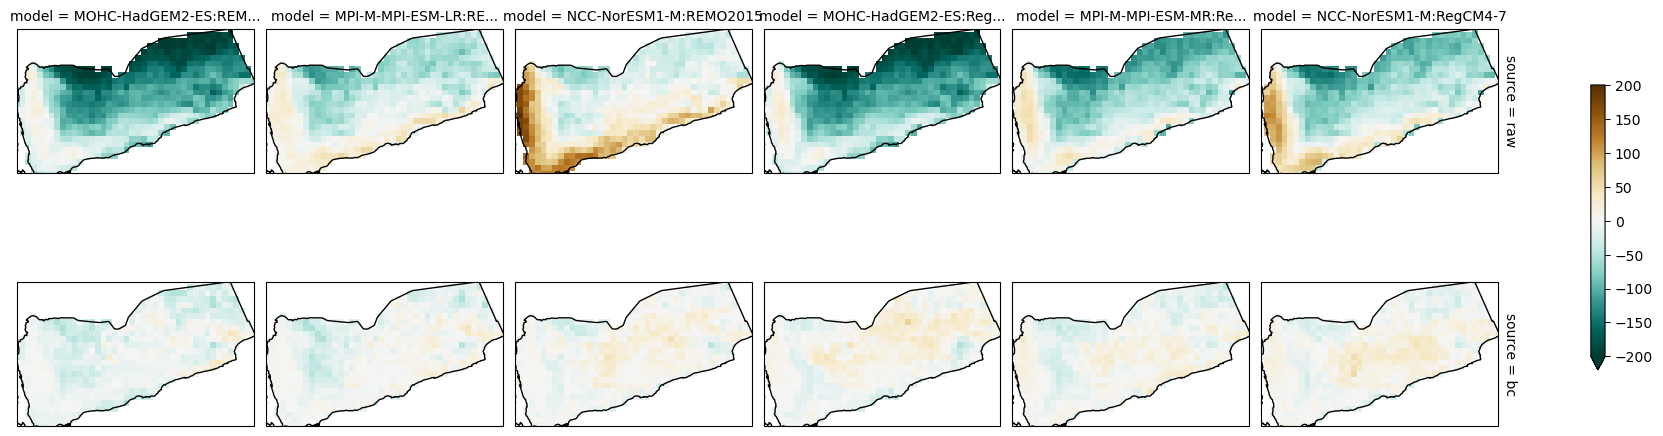

In [22]:
plot = CDD.where(mask).plot(col="model", row="source", vmin=-200, vmax=200, cmap="BrBG_r",
             subplot_kws=dict(projection=ccrs.PlateCarree(central_longitude=0)),
             cbar_kwargs={"shrink": .5},
             transform=ccrs.PlateCarree())

for ax in plot.axs.flatten():
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS, linewidth=1, edgecolor="black")
    ax.set_extent((min_lon, max_lon, min_lat, max_lat), ccrs.PlateCarree())

## CWD

In [23]:
cwd_daily_raw     = xarray.apply_ufunc(
    count_longest_event,
    ((ds_raw["pr"] * 86400) > 1).groupby("time.year"),
    input_core_dims=[["time"]],
    output_core_dims=[[]],
    vectorize=True,
    output_dtypes=[int]).rename({"year": "time"})

cwd_daily_bc     = xarray.apply_ufunc(
    count_longest_event,
    ((ds_bc["pr"] * 86400) > 1).groupby("time.year"),
    input_core_dims=[["time"]],
    output_core_dims=[[]],
    vectorize=True,
    output_dtypes=[int]).rename({"year": "time"})

cwd_daily_era5     = xarray.apply_ufunc(
    count_longest_event,
    ((era5["tp"] * 1000) > 1).groupby("time.year"),
    input_core_dims=[["time"]],
    output_core_dims=[[]],
    vectorize=True,
    output_dtypes=[int]).rename({"year": "time"})

In [24]:
CWD_raw = cwd_daily_raw.mean("time") - cwd_daily_era5.mean("time")
CWD_bc  = cwd_daily_bc.mean("time") - cwd_daily_era5.mean("time")

CWD = xarray.concat([CWD_raw, CWD_bc], dim=xarray.IndexVariable("source", ["raw", "bc"]))

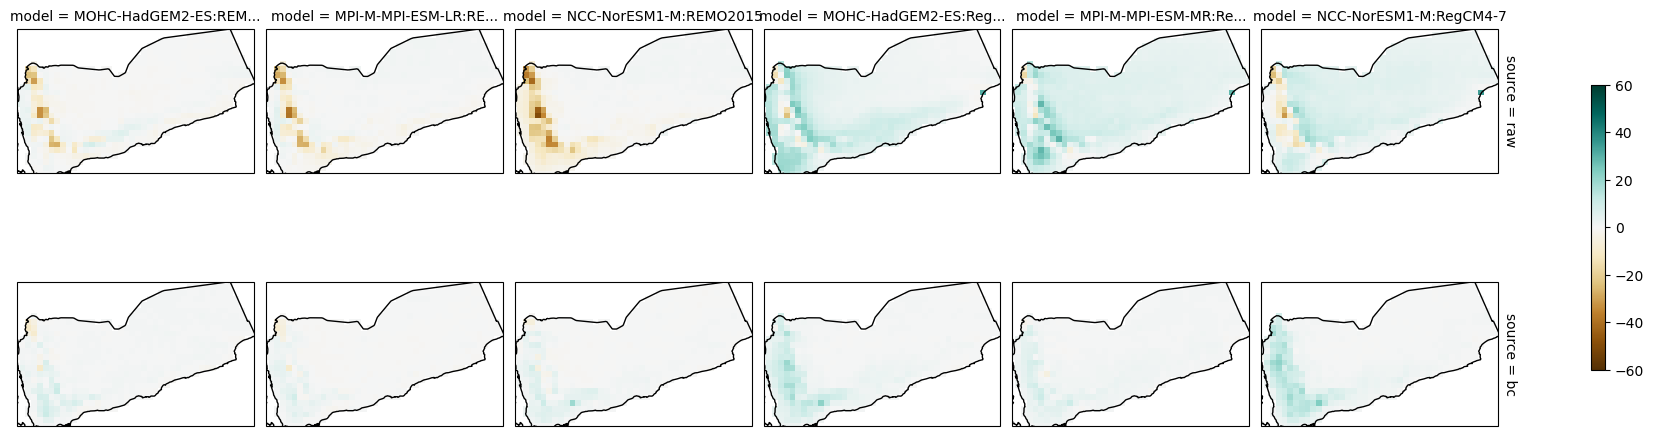

In [25]:
plot = CWD.where(mask).plot(col="model", row="source", vmin=-60, vmax=60, cmap="BrBG",
             subplot_kws=dict(projection=ccrs.PlateCarree(central_longitude=0)),
             cbar_kwargs={"shrink": .5},
             transform=ccrs.PlateCarree())

for ax in plot.axs.flatten():
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS, linewidth=1, edgecolor="black")
    ax.set_extent((min_lon, max_lon, min_lat, max_lat), ccrs.PlateCarree())

## R20

In [26]:
# Very heavy precipitation days
r20_daily_raw = ((ds_raw["pr"] * 86400) > 20).resample({"time": "ME"}).mean()
r20_daily_bc  = ((ds_bc["pr"] * 86400) > 20).resample({"time": "ME"}).mean()
r20_daily_era5 = ((era5["tp"] * 1000) > 20).resample({"time": "ME"}).mean()

In [27]:
R20_raw = r20_daily_raw.sum("time") - r20_daily_era5.sum("time")
R20_bc  = r20_daily_bc.sum("time") - r20_daily_era5.sum("time")

R20 = xarray.concat([R20_raw, R20_bc], dim=xarray.IndexVariable("source", ["raw", "bc"]))


R20.attrs["long_name"] = "N° days"

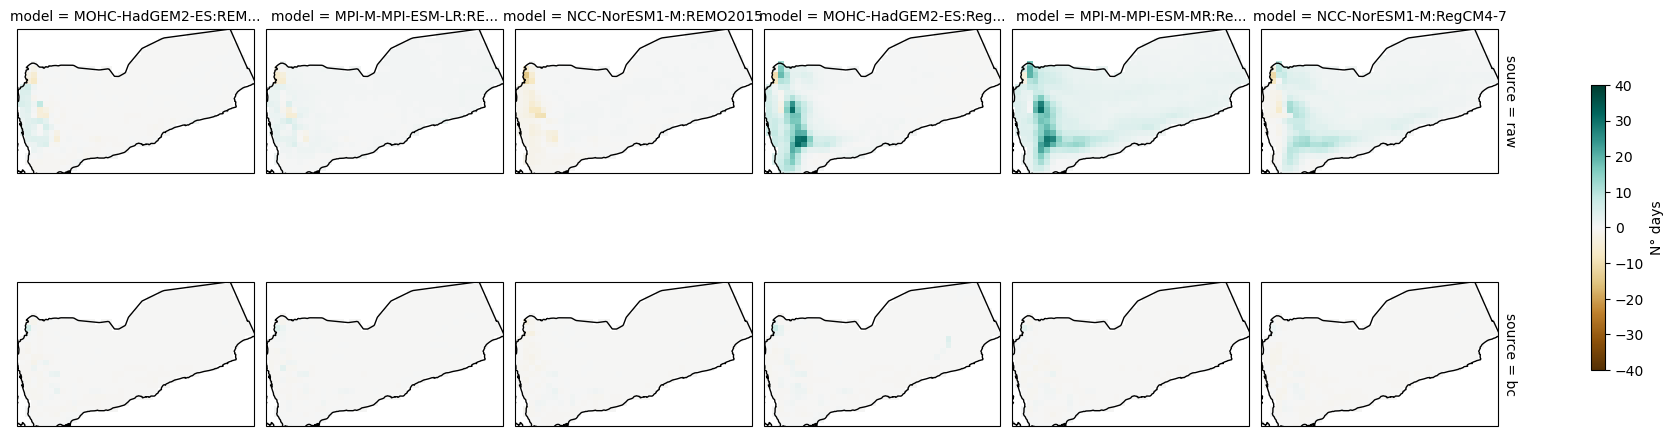

In [28]:
plot = R20.where(mask).plot(col="model", row="source", vmin=-40, vmax=40, cmap="BrBG",
             subplot_kws=dict(projection=ccrs.PlateCarree(central_longitude=0)),
             cbar_kwargs={"shrink": .5},
             transform=ccrs.PlateCarree())

for ax in plot.axs.flatten():
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS, linewidth=1, edgecolor="black")
    ax.set_extent((min_lon, max_lon, min_lat, max_lat), ccrs.PlateCarree())

## SU

In [29]:
su_daily_raw      = ((ds_raw["tasmax"] - 273.15) > 25).resample({"time": "ME"}).mean() #.resample({"time": "YE"}).sum()
su_daily_bc       = ((ds_bc["tasmax"] - 273.15) > 25).resample({"time": "ME"}).mean() #.resample({"time": "YE"}).sum()
su_daily_era5     = ((era5["t2mx"] - 273.15) > 25).resample({"time": "ME"}).mean() #.resample({"time": "YE"}).sum()

In [30]:
SU_raw = su_daily_raw.sum("time") - su_daily_era5.sum("time")
SU_bc  = su_daily_bc.sum("time") - su_daily_era5.sum("time")

SU = xarray.concat([SU_raw, SU_bc], dim=xarray.IndexVariable("source", ["raw", "bc"]))

SU.attrs["long_name"] = "N° days"

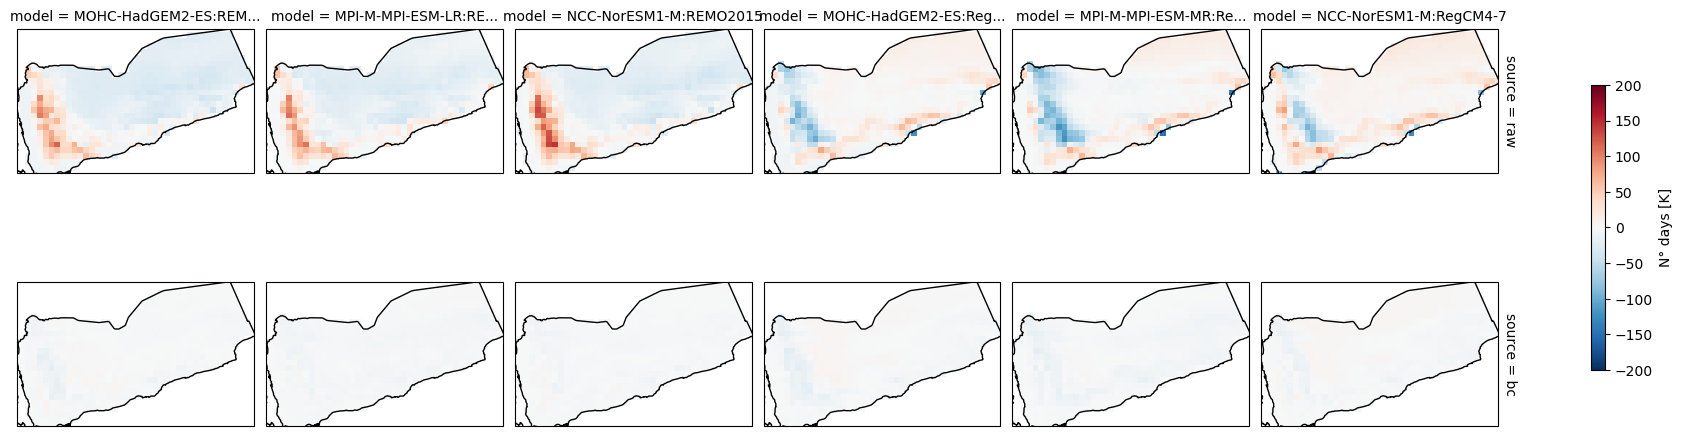

In [31]:
plot = SU.where(mask).plot(col="model", row="source", vmin=-200, vmax=200, cmap="RdBu_r",
             subplot_kws=dict(projection=ccrs.PlateCarree(central_longitude=0)),
             cbar_kwargs={"shrink": .5},
             transform=ccrs.PlateCarree())

for ax in plot.axs.flatten():
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS, linewidth=1, edgecolor="black")
    ax.set_extent((min_lon, max_lon, min_lat, max_lat), ccrs.PlateCarree())

## TR

In [32]:
tr_daily_raw      = ((ds_raw["tasmin"] - 273.15) > 20).resample({"time": "ME"}).mean() #.resample({"time": "YE"}).sum()
tr_daily_bc       = ((ds_bc["tasmin"] - 273.15) > 20).resample({"time": "ME"}).mean() #.resample({"time": "YE"}).sum()
tr_daily_era5     = ((era5["t2mn"] - 273.15) > 20).resample({"time": "ME"}).mean() #.resample({"time": "YE"}).sum()

In [33]:
TR_raw = tr_daily_raw.sum("time") - tr_daily_era5.sum("time")
TR_bc  = tr_daily_bc.sum("time") - tr_daily_era5.sum("time")

TR = xarray.concat([TR_raw, TR_bc], dim=xarray.IndexVariable("source", ["raw", "bc"]))

TR.attrs["long_name"] = "N° days"

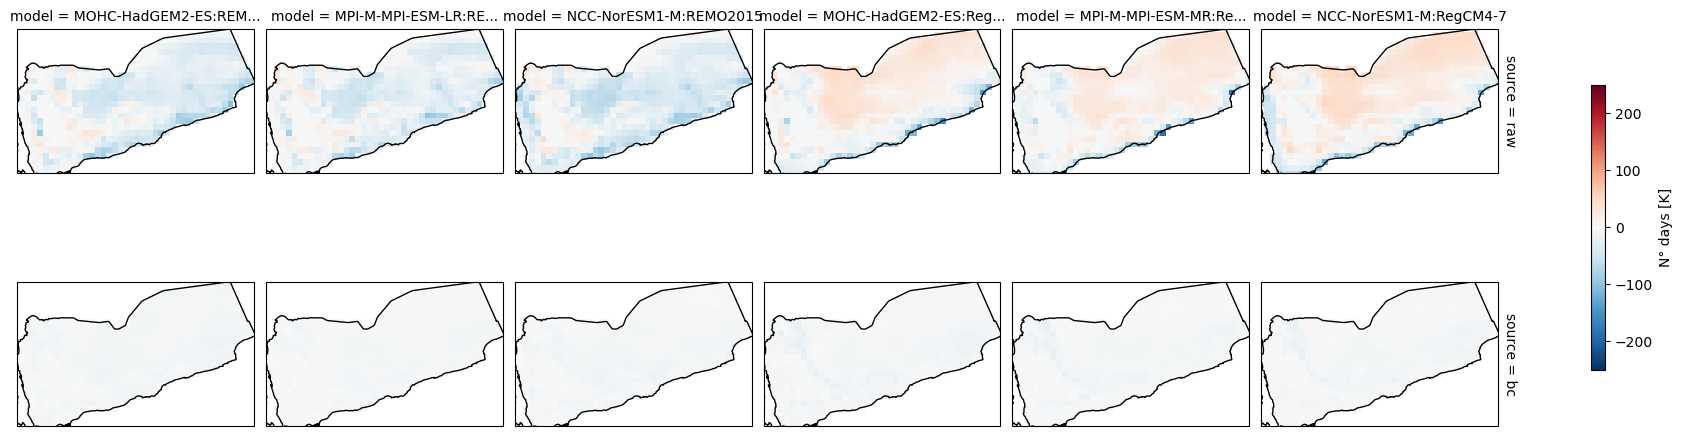

In [34]:
plot = TR.where(mask).plot(col="model", row="source", vmin=-250, vmax=250, cmap="RdBu_r",
             subplot_kws=dict(projection=ccrs.PlateCarree(central_longitude=0)),
             cbar_kwargs={"shrink": .5},
             transform=ccrs.PlateCarree())

for ax in plot.axs.flatten():
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS, linewidth=1, edgecolor="black")
    ax.set_extent((min_lon, max_lon, min_lat, max_lat), ccrs.PlateCarree())

## HWVS

In [35]:
hwvs_daily_raw    = xarray.apply_ufunc(
    lambda x: count_events(x, 3),
    ((ds_raw["tasmax"] - 273.15) > 35).groupby("time.year"),
    input_core_dims=[["time"]],
    output_core_dims=[[]],
    vectorize=True,
    output_dtypes=[int]).rename({"year": "time"})

hwvs_daily_bc     = xarray.apply_ufunc(
    lambda x: count_events(x, 3),
    ((ds_bc["tasmax"] - 273.15) > 35).groupby("time.year"),
    input_core_dims=[["time"]],
    output_core_dims=[[]],
    vectorize=True,
    output_dtypes=[int]).rename({"year": "time"})

hwvs_daily_era5    = xarray.apply_ufunc(
    lambda x: count_events(x, 3),
    ((era5["t2mx"] - 273.15) > 35).groupby("time.year"),
    input_core_dims=[["time"]],
    output_core_dims=[[]],
    vectorize=True,
    output_dtypes=[int]).rename({"year": "time"})

In [36]:
HWVS_raw = hwvs_daily_raw.mean("time") - hwvs_daily_era5.mean("time")
HWVS_bc  = hwvs_daily_bc.mean("time") - hwvs_daily_era5.mean("time")

HWVS = xarray.concat([HWVS_raw, HWVS_bc], dim=xarray.IndexVariable("source", ["raw", "bc"]))

HWVS.attrs["long_name"] = "N° days"

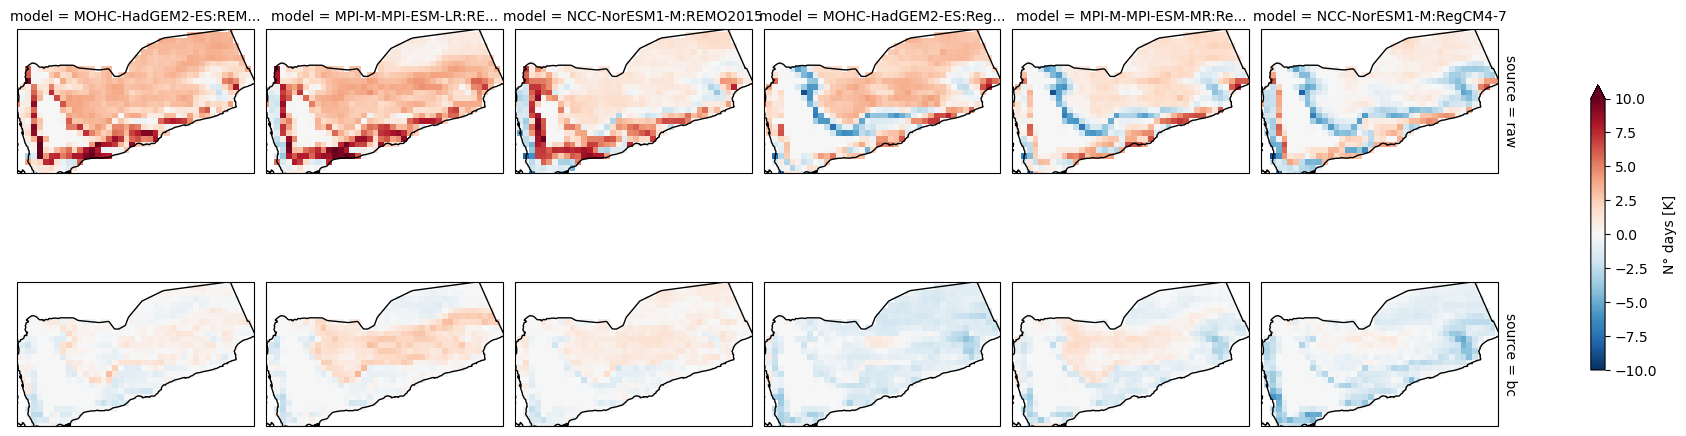

In [37]:
plot = HWVS.where(mask).plot(col="model", row="source", vmin=-10, vmax=10, cmap="RdBu_r",
             subplot_kws=dict(projection=ccrs.PlateCarree(central_longitude=0)),
             cbar_kwargs={"shrink": .5},
             transform=ccrs.PlateCarree())

for ax in plot.axs.flatten():
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS, linewidth=1, edgecolor="black")
    ax.set_extent((min_lon, max_lon, min_lat, max_lat), ccrs.PlateCarree())

In [39]:
# %%time

# yemen = cavapy.get_climate_data(
#     country="Yemen",
#     variables=["tasmax", "tasmin", "pr"],
#     cordex_domain="AFR-22",
#     rcp="rcp26",
#     years_up_to=2030,
#     dataset="CORDEX-CORE-BC",
# )